## **Learning objectives**

By the end of this notebook, you should be able to:

* Understand how to train and implement Naive Bayes classifiers.
* Understand how the log loss function works and how it differs from other classification metrics.
* Understand how to train and implement k-nearest neighbours.

### 1.1 **Naive Bayes theory**


Naive Bayes is a classification algorithm that uses the principle of [Bayes' theorem](https://en.wikipedia.org/wiki/Bayes%27_theorem) to make classifications.

The benefits of Naive Bayes are that the model is **simple** to build and is useful on **large datasets**.

Further, the model makes an explicit **assumption** that the **features are independent** given the class label. What does this mean? Well first let's consider the concept of independence. Independence is a concept from probability theory and it implies that if we have two random variables $X$ and $Y$, then

$$
P(X \cap Y) = P(X)P(Y)
$$

This is where the qualifier "Naive" in "Naive Bayes" comes from. The assumption is *Naive* because it often does not hold. The assumption of independence implies that the model assumes that there is **zero correlation** among the features. Hence, the joint probability distribution $P(X, Y)$ can be obtained from the marginal probability distributions $P(X)$ and $P(Y)$ simply by multiplication. We will use the above independence assumption, conditional probability rules, and Bayes' theorem to develop some theory for how the Naive Bayes model works.

Next, let's consider Bayes' theorem. Bayes' theorem is an important result in statistics and it allows us to obtain a posterior distribution given a prior distribution and a likelihood. Now that is a mouthful, but don't worry, we will walk you through it. First, let's denote class labels using $K = 1, \cdots, k$ – seem familiar? What we are trying to say here is that each class label corresponds to a number between $1$ and $k$. So, given this, the independence assumption conditional on the class label is denoted:

$$
P(X_{1} \cap X_{2} \mid K = k) = P(X_{1} \mid K = k)P(X_{2} \mid K = k)
$$

In the expression above, $X_{1}$ and $X_{2}$ denote random predictor variables. Keep this in mind. Bayes' theorem states that

$$
P(K = k \mid X) = \frac{P(X \mid K= k) P(K = k)}{P(X)}
$$

In the expression above:

- $P(K = k \mid X)$ is called the _posterior probability_ distribution.

- $P(K = k)$ is the *prior*.

- $P(X \mid K= k)$ is the _likelihood_.

The posterior tells us what the probability is of the class being $k$ given a particular observation. The prior is basically a measure of how likely we think it is for any observation to be assigned to a particular class before we have observed any observations. The likelihood gives us a measure of what the data says about the probability that the observation belongs to class $k$.

That's it. In principle, this is how the Naive Bayes model works (i.e. with two predictor variables and $k$ classes). Here's the general algorithm:

1. For each class $k$:

    - Find the likelihood $P(X_{1} \cap X_{2} \mid K = k) = P(X_{1} \mid K = k)P(X_{2} \mid K = k)$, using only the observations where the class is $k$ in the data.
    - Compute a prior probability for the current class $k$ = $\frac{observations \space in \space class \space k}{total \space number \space of \space observations}$.
    - Use Bayes' theorem, with a denominator (i.e. the evidence $P(X)$) of $1$, to compute the posterior probability distribution.


2. At test time, observations are assigned to classes with the highest posterior probability $P(X_{1} \cap X_{2} \mid K = k)$.

Now that we've covered the intuition, let's generalise the model to include an arbitrary number of random predictor variables instead of 2, i.e.

$$
X_{1}, \cdots, X_{p}
$$

In this case:

$$
P(K = k \mid X_{1} \cap X_{2} \cdots \cap X_{p}) = \frac{P(X_{1} \cap X_{2} \cdots \cap X_{p} \mid K= k) P(K = k)}{P(X)}
$$

Now remember the assumption in the back of your mind. This allows us to simplify the expression above to become:

$$
P(K = k \mid X_{1} \cap X_{2} \cdots \cap X_{p}) = \frac{P(X_{1}\mid K= k) P(X_{2}\mid K= k) \cdots P(X_{p}\mid K= k) P(K = k)}{P(X)}
$$

A special mathematical symbol allows us to represent the product $P(X_{1}\mid K= k) P(X_{2}\mid K= k) \cdots P(X_{p}\mid K= k)$ as $\prod_{i = 1}^{p} P(X_{i}\mid K= k)$. Hence, the expression above becomes:

$$
P(K = k \mid X_{1} \cap X_{2} \cdots \cap X_{p}) = \frac{\prod_{i = 1}^{p} P(X_{i}\mid K= k)P(K = k)}{P(X)}
$$

Now let's consider how the Bayes classifier assigns observations to a particular class. One method, called [maximum a posteriori (MAP)](https://en.wikipedia.org/wiki/Maximum_a_posteriori_estimation), maximises $P(K = k \mid X_{1} \cap X_{2} \cdots \cap X_{p})$ for $K = 1, \cdots, k$ to assign the observation to the correct class. Let's consider what this means for $K = 2$. In this case we calculate:

$$
P(K = 1 \mid X_{1} \cap X_{2} \cdots \cap X_{p}) \\
P(K = 2 \mid X_{1} \cap X_{2} \cdots \cap X_{p}) \\
$$

If $P(K = 1 \mid X_{1} \cap X_{2} \cdots \cap X_{p}) > P(K = 2 \mid X_{1} \cap X_{2} \cdots \cap X_{p})$ then we say that the observation $\underline{X}$ is assigned to class $1$ else it is assigned to class $2$. This concept can be generalised to more classes. We just want to make something clear here.

An observation, i.e. something that actually happened, is denoted:

$$
\underline{x}_{i} = (x_{i,1}, x_{i,2}, \cdots, x_{i,p})
$$

But a set of random variables, which captures all possible things that can happen for all observations, is denoted:

$$
\underline{X} = (X_{1}, X_{2}, \cdots, X_{p})
$$

Using this notation, $X_{i}, i = 1 \cdots, p$ denotes a feature. Let's get to some code.

### 1.2 **Naive Bayes in Scikit learn**

`sklearn` provides three implementations of the Naive Bayes method:

   a) **Gaussian:** It is used in classification and it assumes that features follow a normal distribution.

   b) **Multinomial:** It is used for discrete counts. For example, let’s say  we have a text classification problem. Here we can consider Bernoulli trials which is one step further, and instead of “word occurring in the document”, we have “count how often word occurs in the document”. You can think of it as “number of times outcome number x_i is observed over the n trials”.

   c) **Bernoulli:** The binomial model is useful if your feature vectors are binary (i.e. zeros and ones). One application would be text classification with a ‘bag of words’ model where the 1s and 0s are “word occurs in the document” and “word does not occur in the document” respectively.

These implementations are merely the choice of our probability distribution $P$. We choose an implementation based on the nature of the features (i.e. predictor variables) in our data.

Source: https://www.analyticsvidhya.com/blog/2017/09/naive-bayes-explained/

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, log_loss

In [101]:
# Load the breast cancer data
X, y = load_breast_cancer(return_X_y=True)

In [102]:
print("Data shape:", X.shape)

Data shape: (569, 30)


In [103]:
print(y.shape)

(569,)


In [104]:
# Get training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Ensure target is 1-dimensional
y_train = np.asarray(y_train).ravel()
y_test = np.asarray(y_test).ravel()

# Define the model
bayes = GaussianNB()

# Fit the model
bayes.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[169.,286.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.37,0.63]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.0003215
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 30)","[[ 17.42, 21.49,115.01,..., 0.18, 0.33, 0.09], [ 12.17, 17.82, 78.21,..., 0.07, 0.27, 0.08]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 30)","[[ 10.74, 14.83,495.88,..., 0. , 0.01, 0. ], [ 3.27, 15.12,143.06,..., 0. , 0. , 0. ]]"


#### **Assess model performance**

So far, we've been using the classification report and confusion matrices to assess classification model performance. However, such metrics don't do a good job at highlighting how confident our model is in its predictions.

Enter the **log loss function** which, unlike other metrics, can penalise predictions based on how confident a model is with those predictions. For example, if our model predicts the wrong class with high probability, the log loss penalises it more (i.e.: assigns higher log loss) compared to a model that predicts the wrong class with low probability.

As such, we generally feed **class probabilities** into the log loss function instead of the actual class predictions (i.e. thresholded probabilities).

For the log loss metric, **lower is better**, i.e. a perfect model would have a log loss of 0.

In [105]:
# Predict class probabilities
y_pred = bayes.predict_proba(X_test)

# Calculate log loss
log_loss_error = log_loss(y_test, y_pred)

print(f"The log loss error: {log_loss_error:.4f}")

The log loss error: 0.2037


#### **Plot the decision boundary**

It is recommended to visualise the decision boundary of our classifier where possible. Unfortunately, in this case, we have around 31 different variables (features + response) and we can visualise only three at a time. So let's do just that.

Below, we create a visualisation which can represent the decision boundary between any two features in $X$. The $y$ (i.e. class label) is indicated by the colour of each data point. The decision boundary is the line separating the two regions of blue and red, such that any point falling into the red region is assigned the red label (class 1), and any point falling into the blue region is assigned the blue label (class 2).

To change which features you want to compare, simply change the values for `i` and `j`.

In [106]:
import seaborn as sns

def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    figsize=(9, 5),
    grid=True,
    remove_spine=True,
    title_fontsize=14,
    label_fontsize=12,
):
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold"
        )

    if xlabel:
        ax.set_xlabel(
            xlabel,
            fontsize=label_fontsize
        )

    if ylabel:
        ax.set_ylabel(
            ylabel,
            fontsize=label_fontsize
        )

    if grid:
        ax.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            alpha=0.3,
            color="0.75"
        )

    if remove_spine:
        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.tick_params(length = 0)

    return ax

In [107]:
# Select two features to visualize
i = 0
j = 1

# Extract the selected features
X_2d = X[:, [i, j]]
y_1d = np.asarray(y).ravel()

# Define and fit Gaussian Naive Bayes
bayes_2d = GaussianNB()
bayes_2d.fit(X_2d, y_1d)

# Create a mesh covering the feature space
x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict the class for every point in the mesh
mesh_points = np.c_[xx.ravel(), yy.ravel()]

mesh_predictions = bayes_2d.predict(mesh_points)
mesh_predictions = mesh_predictions.reshape(xx.shape)


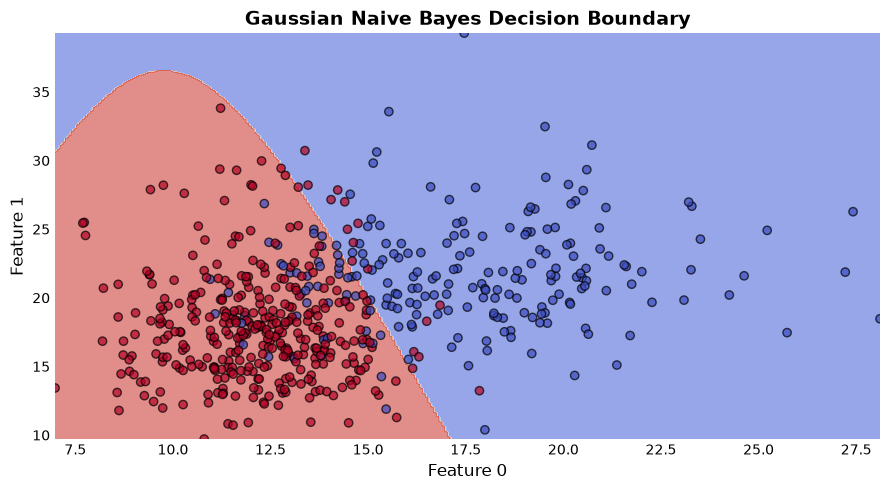

In [108]:
# Create the plot
fig, ax = plt.subplots(figsize=(9, 5))

# Plot decision regions
ax.contourf(
    xx,
    yy,
    mesh_predictions,
    cmap = "coolwarm",
    alpha=0.6
)

# Plot observations
ax.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y_1d,
    cmap='coolwarm',
    edgecolor="k",
    alpha=0.7
)

# Apply standard plot style
style_plot(
    ax,
    title="Gaussian Naive Bayes Decision Boundary",
    xlabel=f"Feature {i}",
    ylabel=f"Feature {j}",
    grid = False
)

plt.tight_layout()
plt.show()

### 2.1 **K-nearest neighbours theory**

K-nearest neighbours (KNN) is a powerful yet easy-to-understand machine learning algorithm. In principle, this algorithm works by assigning the majority class of the N closest neighbours to the current data point. As such, absolutely no training is required for the algorithm! All we do is choose k (i.e. the number of neighbours to consider), choose a distance function to calculate proximity, and we're good to go.

A typical KNN algorithm works as follows:

1. Choose k (number of neighbours).
2. Choose distance metric, e.g. Euclidean distance:
$$
d(X^a,X^b) = \sqrt{(x^{a}_{1}-x^{b}_{1})^2 + (x^{a}_{2}-x^{b}_{2})^2 + \cdots + (x^{a}_{n}-x^{b}_{n})^2}
$$
3. For each data point $X_{test}$ in the testing data:
    - For each data point $X_{train}$ in the training data:
        - Calculate the distance $d(X_{train},X_{test})$ between the test point and training observation.
    - Find labels of the k closest data points to $X_{test}$
    - Assign most-frequent (i.e. the mode) class label to $X_{test}$.

In the context of regression, we would use the mean of the K-nearest neighbours instead of the mode of the class labels.

In [109]:
n_neighbors = 3

knn = KNeighborsClassifier(n_neighbors)
# Fit the model 
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [110]:
y_hat = knn.predict_proba(X_test)

print(f"The log loss error of the KNN model is {log_loss(y_test, y_hat):.4f}")

The log loss error of the KNN model is 0.4085


__Note__

Notice that the log loss is higher than it was for the Naive Bayes model. 

In [111]:
# Select two features to visualize
feature1 = 0
feature2 = 1

# Extract the selected features
X_selected = X[:, [feature1, feature2]]
y_selected = np.asarray(y).ravel()

# Define and fit Gaussian Naive Bayes
knn_2d = KNeighborsClassifier(n_neighbors)
knn_2d.fit(X_selected, y_selected)

# Create a mesh covering the feature space
min_x, max_x = X_selected[:, 0].min(), X_selected[:, 0].max()
min_y, max_y = X_selected[:, 1].min(), X_selected[:, 1].max()

xx, yy = np.meshgrid(
    np.linspace(min_x, max_x, 300),
    np.linspace(min_y, max_y, 300)
)

# Predict the class for every point in the mesh
mesh = np.c_[xx.ravel(), yy.ravel()]

mesh_preds = knn_2d.predict(mesh)
mesh_preds = mesh_preds.reshape(xx.shape)

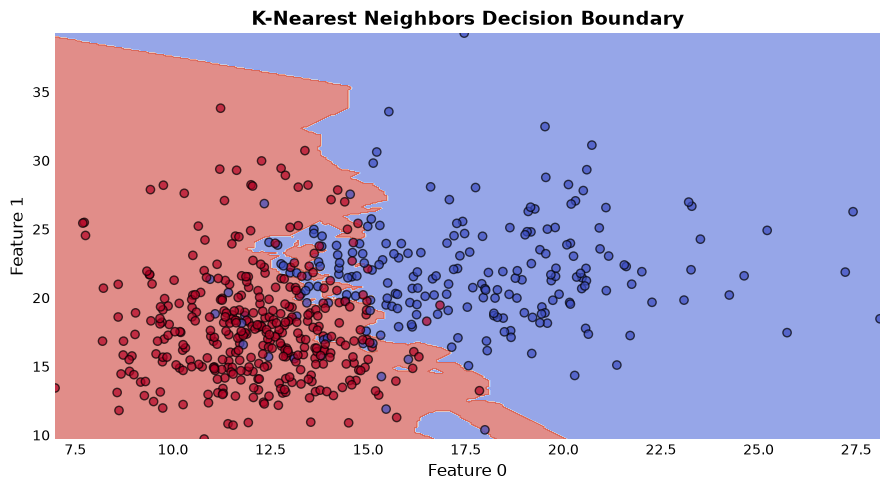

In [112]:
# Create the plot
fig, ax = plt.subplots(figsize=(9, 5))

# Plot decision regions
ax.contourf(
    xx,
    yy,
    mesh_preds,
    cmap="coolwarm",
    alpha=0.6
)

# Plot observations
ax.scatter(
    X_selected[:, 0],
    X_selected[:, 1],
    c=y_1d,
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.7
)

# Apply standard plot style
style_plot(
    ax,
    title="K-Nearest Neighbors Decision Boundary",
    xlabel=f"Feature {feature1}",
    ylabel=f"Feature {feature2}",
    grid=False
)

fig.tight_layout()
plt.show()

__Reflect__

> **In KNN, what role does the value of k play in the prediction, and what trade-off does a very small or very large k introduce?**

__Explanation__

In **K-Nearest Neighbors (KNN)**, **k** determines how many of the nearest observations are considered when making a prediction.

* **Small k** (e.g., `k = 1`): The model looks at very few neighbors. It can capture fine details in the data but is **sensitive to noise and prone to overfitting**.

* **Large k** (e.g., `k = 50`): The model considers many neighbors, producing a smoother decision boundary. However, it may **ignore important local patterns and underfit**.

### Trade-off

-  **Small k → low bias, high variance → more complex boundary → risk of overfitting.**
- **Large k → high bias, low variance → smoother boundary → risk of underfitting.**

Therefore, **k should be chosen carefully**, usually using validation or cross-validation to find a value that balances bias and variance.


__Question__

Naive Bayes assumes features are conditionally independent given the class label. Why might that assumption be unrealistic in practice, and why can the classifier still perform well?

__Answer__

The **conditional independence assumption** may be unrealistic because features in real-world data are often related to one another. For example, in a medical dataset, **age, blood pressure, and cholesterol** may be correlated rather than independent.

However, Naive Bayes can still perform well because:

* It needs to estimate **far fewer parameters**, making it fast and less prone to overfitting, especially with limited data.
* Even when independence is not strictly true, the model can still estimate the **relative probability of each class reasonably well**.
* Classification often depends more on getting the **correct ranking of class probabilities** than on perfectly estimating the true joint probability distribution.

**In short:** the independence assumption is mathematically strong but can be surprisingly effective in practice because Naive Bayes is simple, computationally efficient, and often robust to moderate feature dependence.


__Question__

**Grid search tests every combination in a defined search space. What are two things you need to decide before you can run a grid search on a classifier?**

__Answer__

Before running a grid search on a classifier, you need to decide:

1. **Which hyperparameters and values to test** — for example, `max_depth`, `n_estimators`, `C`, or `k`, and the specific values for each.
2. **Which evaluation strategy/metric to use** — for example, cross-validation with **accuracy, precision, recall, F1-score, or ROC-AUC** to determine which combination performs best.

**In short:** define the **search space** and the **evaluation method/metric**.





__Question__

**A decision tree has a hyperparameter called max_depth. Is max_depth something the tree learns from your training data, or something you set before training begins? What is the practical difference?**

__Answer__

`max_depth` is a **hyperparameter**, so it is something you **set before training** (or choose through a tuning process such as grid search). The decision tree does **not learn the value of `max_depth` from the training data**.

### **Practical difference**

* **Hyperparameter (`max_depth`)** → set by you before training. It controls the model's complexity. For example, `max_depth=3` limits how deep the tree can grow.
* **Model parameters** → learned from the training data. For a decision tree, these include the **features and split points** the tree chooses at each node.

For example:

```python
DecisionTreeClassifier(max_depth=5)
```

Here, **5 is set by you**, while the tree learns **where to split the data**.

**In short:** `max_depth` controls the model's complexity, while the tree's splits are learned from the data.


__Question__

**If you tune your hyperparameters by checking performance on the test set, why might your final accuracy be misleading?**

__Answer__

If you tune hyperparameters using the **test set**, your final accuracy may be misleading because the test data is no longer truly **unseen**.

By repeatedly checking test-set performance and choosing the hyperparameters that perform best, you are indirectly **optimising the model for the test set**. This can cause the model to overfit to the test data, making the reported accuracy look better than its performance on genuinely new data.

**Best practice:**

* **Training set** → fit the model.
* **Validation set / cross-validation** → tune hyperparameters.
* **Test set** → evaluate the final model **once**.

**In short:** using the test set for tuning causes **data leakage** and can produce an overly optimistic estimate of the model's real-world performance.


## __What is a hyperparameter?__

A hyperparameter is a variable or argument whose value is set before the training process begins. In contrast, _parameters_ are those values derived via training. Different model training algorithms require different hyperparameters, and some simple algorithms require none.

[**Hyperparameter optimisation**](https://en.wikipedia.org/wiki/Hyperparameter_optimization), or tuning, is the method of choosing a set of optimal hyperparameters for a learning algorithm.

The same type of machine learning model can require different constraints, weights or learning rates to generalise to different data patterns. Hyperparameter optimisation finds a tuple of hyperparameters that yields an optimal model which minimises a predefined loss function on given data.



Various techniques exist for tuning hyperparameters, to name a few:

* Grid search;
* Random search;
* Bayesian optimisation;
* Gradient-based optimisation; and
* Evolutionary optimisation.

In this tutorial we will be implementing Grid Search and leave the exploration of other techniques as an exercise for the reader.

### **Imports**

Let us start off as usual, by importing all the necessary packages.

In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [114]:
path = "../data/mbti.csv"
mbti = pd.read_csv(path)


In [115]:
mbti.head(4)

,actually,agree,ask,away,bad,believe,best,better,bit,care,...,work,world,wouldnt,wrong,yeah,year,years,yes,youre,y
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [116]:
X = mbti.drop('y', axis=1)
y = mbti['y']

n = 5000
X_n = X[:n]
y_n = y[:n]
X_train, X_test, y_train, y_test = train_test_split(X_n, y_n)

## __K-Nearest Neigbours__

Let's start with the K-Nearest Neighbours algorithm as it has one of the more simple hyperparameters:
* `K` - the number of nearest neighbours to use in the classifier

In this example, we'll create 13 different KNN models, each with a different number of neighbours. We'll generate the results of both the training and testing accuracy in order to analyse the performance of each of these models. Note that this cell might take more time to complete than you are used to, as we are now training 13 models instead of 1.

**Note: The code below takes 1-2 minutes to execute.**

In [117]:
import time

ks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 50, 100]

results = []

for k in ks:
    print(f"Fitting KNN model with k = {k}")

    # Define and fit the model
    knn = KNeighborsClassifier(n_neighbors=k)

    start_time = time.perf_counter()
    knn.fit(X_train, y_train)
    run_time = time.perf_counter() - start_time

    # Predictions
    y_pred_train = knn.predict(X_train)
    y_pred_test = knn.predict(X_test)

    # Training metrics
    accuracy_train = metrics.accuracy_score(y_train, y_pred_train)
    precision_train = metrics.precision_score(y_train, y_pred_train)
    recall_train = metrics.recall_score(y_train, y_pred_train)
    f1_train = metrics.f1_score(y_train, y_pred_train)

    # Test metrics
    accuracy_test = metrics.accuracy_score(y_test, y_pred_test)
    precision_test = metrics.precision_score(y_test, y_pred_test)
    recall_test = metrics.recall_score(y_test, y_pred_test)
    f1_test = metrics.f1_score(y_test, y_pred_test)

    # Save results
    results.append([
        k,
        accuracy_train,
        precision_train,
        recall_train,
        f1_train,
        accuracy_test,
        precision_test,
        recall_test,
        f1_test,
        run_time
    ])

# Create results DataFrame
results = pd.DataFrame(
    results,
    columns=[
        "KNN",
        "Accuracy Train",
        "Precision Train",
        "Recall Train",
        "F1 Train",
        "Accuracy Test",
        "Precision Test",
        "Recall Test",
        "F1 Test",
        "Train Time"
    ]
)

results.set_index("KNN", inplace=True)

results

Fitting KNN model with k = 1
Fitting KNN model with k = 2
Fitting KNN model with k = 3
Fitting KNN model with k = 4
Fitting KNN model with k = 5
Fitting KNN model with k = 6
Fitting KNN model with k = 7
Fitting KNN model with k = 8
Fitting KNN model with k = 9
Fitting KNN model with k = 10
Fitting KNN model with k = 20
Fitting KNN model with k = 50
Fitting KNN model with k = 100


,Accuracy Train,Precision Train,Recall Train,F1 Train,Accuracy Test,Precision Test,Recall Test,F1 Test,Train Time
KNN,,,,,,,,,
1,0.950933,0.946446,0.992374,0.968866,0.6736,0.780296,0.810645,0.795181,0.010968
2,0.814933,0.949528,0.802080,0.869598,0.5984,0.797247,0.651996,0.717342,0.007790
3,0.813067,0.825387,0.960139,0.887678,0.7376,0.790510,0.903787,0.843362,0.007678
4,0.794933,0.841952,0.902946,0.871383,0.7008,0.792435,0.836233,0.813745,0.006041
5,0.783467,0.793211,0.971924,0.873520,0.7632,0.792777,0.943705,0.861682,0.006173
6,0.782667,0.804412,0.948007,0.870326,0.7456,0.792889,0.912999,0.848716,0.005575
7,0.778933,0.783978,0.983709,0.872560,0.7736,0.787252,0.973388,0.870481,0.006569
8,0.778133,0.792533,0.963951,0.869878,0.7688,0.793015,0.952917,0.865644,0.006206
9,0.776267,0.777989,0.992374,0.872201,0.7792,0.784728,0.988741,0.875000,0.006882


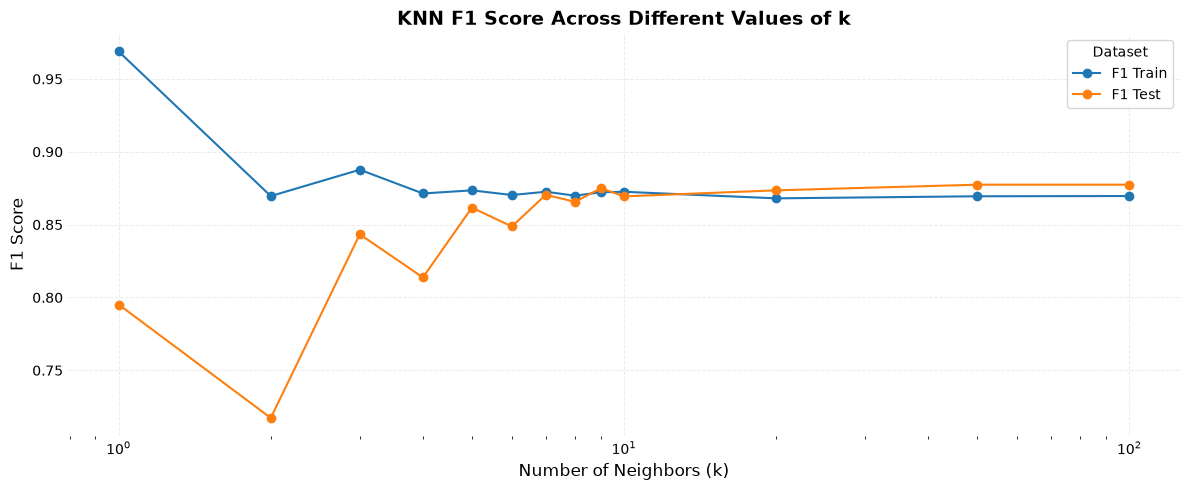

In [118]:
fig, ax = plt.subplots(figsize = (12, 5))

results[['F1 Train', 'F1 Test']].plot(
    kind='line',
    ax=ax,
    marker='o',
    logx=True
)

style_plot(
    ax,
    title="KNN F1 Score Across Different Values of k",
    xlabel="Number of Neighbors (k)",
    ylabel="F1 Score",
)

ax.legend(title="Dataset")
fig.tight_layout()
plt.show()

The optimal choice for $k$ based on this validation curve is **$k \approx 9$** (or the peak around **$k = 6$ to $9$** depending on preferred trade-offs).

**Why:**

* **Peak Test Performance**: The highest orange point (**F1 Test**) occurs around $k = 9$ (just under $10^1$), achieving an F1 score of $\approx 0.865$.
* **Low Generalization Gap**: At this region, the gap between the training score (blue) and the testing score (orange) is minimized while keeping overall accuracy high.
* **Underfitting vs. Overfitting**:
* **Small $k$ ($10^0 = 1$)**: High variance / overfitting. Training F1 is near $0.97$, but Test F1 lags behind ($\approx 0.79$).
* **Large $k$ ($> 20$ to $10^2$)**: High bias / underfitting. Both train and test curves flatten completely into a majority-class prediction plateau ($\approx 0.87$).

### **`sklearn` GridSearch**

Hyperparameter tuning can be automated using `sklearn`'s parameter search strategies. As in the example above where we exhaustively consider all parameter combinations (or at least most of the parameters between `K` = 1 and 100), this can be done using the search strategy `GridSearchCV`. Let's see how that works.

#### **Imports**

We'll need to import `GridSearchCV`.

In [119]:
from sklearn.model_selection import GridSearchCV

In [120]:
ks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 50, 100]

# ks is the list of k-values we created above
param_grid = {'n_neighbors': ks}


grid_search = GridSearchCV(
    KNeighborsClassifier(), 
    param_grid, 
    scoring = "f1"
)

In [121]:
grid_knn = grid_search.fit(X_n, y_n)

print(f"Best parameters: {grid_knn.best_params_}")

Best parameters: {'n_neighbors': 50}


## **Support vector machine**

Models generally have more than one hyperparameter to tune.  `sklearn` provides automated tools to do this in the grid search module. we'll now work through an example of using grid search to find the optimal hyperparameters for a Support Vector Machine.

The grid search algorithm will fit a model for all of the combinations of hyperparameters you specify. It will also apply K-fold cross-validation. The hyperparameters that optimise for a given scoring metric will then be returned.

Let's start by importing `sklearn`'s Support Vector Classifier.

In [122]:
from sklearn.svm import SVC

There are a lot of parameters in SVC to play around with!  We will be focussing on the following:

* `C`: The penalty parameter of the error term; and
* `gamma`: The kernel coefficient.

In this example, we'll set the number of folds in our cross validation to 2, we'll optimise using F1-score, and tune the two above mentioned parameters. `sklearn` really does make this simple for us.

In [132]:
nfolds = 2

Cs = [0.001, 0.01, 0.1, 1, 10]
gammas = [0.001, 0.01, 0.1, 1]

param_grid_1 = {
    'C': Cs,
    'gamma': gammas
}

grid_SVM = GridSearchCV(
    SVC(),
    param_grid_1,
    scoring='f1',
    cv=nfolds
)

grid_SVM.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...], 'gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with 

### **What happens here**

There are:

* **5 values of `C`**
* **4 values of `gamma`**
* **20 parameter combinations** in total
* **2-fold cross-validation** for each combination

So GridSearchCV evaluates:

**20 × 2 = 40 model fits**

### **Meaning of the parameters**

| Parameter      | Controls                                                      |
| -------------- | ------------------------------------------------------------- |
| `C`            | Penalty for classification errors                             |
| `gamma`        | Influence/range of individual observations with an RBF kernel |
| `cv=2`         | Splits training data into 2 folds                             |
| `scoring='f1'` | Selects the model with the highest F1 score                   |

For an RBF SVM:

* **Small `C`** → stronger regularization → simpler decision boundary
* **Large `C`** → weaker regularization → more complex boundary
* **Small `gamma`** → smoother, broader influence
* **Large `gamma`** → tighter, more complex boundary

**Important:** `GridSearchCV` uses only `X_train, y_train` for tuning. Keep `X_test, y_test` untouched until the final evaluation.


In [134]:

print(grid_SVM.best_params_)

{'C': 10, 'gamma': 0.01}


In [135]:
# Best cross-validation F1:

print(grid_SVM.best_score_)

0.8696699671083583


In [136]:
# And the actual best SVM model:
print(grid_SVM.best_estimator_)

SVC(C=10, gamma=0.01)


In [137]:
# Then evaluate it on your **test set**:

y_pred = grid_SVM.predict(X_test)

print(metrics.f1_score(y_test, y_pred))
print(metrics.classification_report(
    y_test, y_pred,
    zero_division=0
    )
)

0.877413560844185
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       273
           1       0.78      1.00      0.88       977

    accuracy                           0.78      1250
   macro avg       0.39      0.50      0.44      1250
weighted avg       0.61      0.78      0.69      1250



> **Although the SVM achieved an F1 score of 0.88 for the positive class, it failed to identify any observations from class 0. The 78% accuracy is largely explained by class imbalance, since class 1 represents approximately 78% of the test set. Therefore, accuracy and positive-class F1 alone overstate the model's overall classification performance.**